<h1><center>Things.</h1></center>

1. Choose your dataset for GAN network, using convolution layers
2. Make network to fail

In [180]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision.transforms import transforms as T
from torchvision.datasets import CIFAR10
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [181]:
transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
]) 

In [182]:
dataset = CIFAR10(root='D:/MIREA/DPO/Learning/Practic2_5/Cifar10',
                  download=False, train=True, transform=transform)
dataset

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: D:/MIREA/DPO/Learning/Practic2_5/Cifar10
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [183]:
dataset.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [184]:
len_classes = len(dataset.classes)
len_classes

10

In [185]:
dataset[0][0].shape

torch.Size([3, 32, 32])

In [186]:
BATCH_SIZE = 32
train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

In [215]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            # nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            # nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 1, kernel_size=4, stride=1, padding=0),
            nn.Flatten(),
            nn.Sigmoid()
        )
    
    def forward(self, X):
        return self.model(X)
    
class Generator(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.ConvTranspose2d(100, 256, kernel_size=4, stride=1, padding=0),
            nn.LeakyReLU(0.2, True),
            
            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2, True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2, True),

            nn.Upsample(scale_factor=2, mode='nearest'),
            nn.Conv2d(64, 3, kernel_size=3, padding=1),
            nn.Tanh()
            
            # Первая версия
            # nn.ConvTranspose2d(100, 256, kernel_size=4, stride=1, padding=0),
            # # nn.BatchNorm2d(256),
            # nn.LeakyReLU(0.2, True),
            
            # nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            # # nn.BatchNorm2d(128),
            # nn.LeakyReLU(0.2, True),

            # nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            # # nn.BatchNorm2d(64),
            # nn.LeakyReLU(0.2, True),

            # nn.ConvTranspose2d(64, 3, kernel_size=4, stride=2, padding=1),
            # nn.Tanh()
        )

    def forward(self, X):
        return self.model(X)

In [216]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}.')

disc = Discriminator()
gen = Generator()

print('Num params of discriminator: %d.' % sum(p.numel() for p in disc.parameters()))
print('Num params of generator: %d.' % sum(p.numel() for p in gen.parameters()))

Device: cuda:0.
Num params of discriminator: 662977.
Num params of generator: 780419.


In [217]:
EPOCHS = 20
# lr = .0002
betas = (0.5, 0.999)
criterion = nn.BCELoss()
optim_disc = torch.optim.Adam(disc.parameters(), lr=2e-4, betas=betas)
optim_gen = torch.optim.Adam(gen.parameters(), lr=5e-5, betas=betas)
disc.to(device)
gen.to(device)

Generator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(128, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Upsample(scale_factor=2.0, mode='nearest')
    (9): Conv2d(64, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): Tanh()
  )
)

In [218]:
from tqdm.notebook import tqdm

for epoch in tqdm(range(EPOCHS)):
    loss_gen_stat = 0.0
    loss_disc_stat = 0.0
    if (epoch % 10 == 0) or (epoch == EPOCHS - 1):
        torch.save(gen.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_12/generator_conv_weights_{epoch}.pt')
        torch.save(disc.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_12/discriminator_conv_weights_{epoch}.pt')
    for n, (real_sample, real_label) in enumerate(tqdm(train_loader)):
        current_batch_size = real_sample.size(0)
        real_sample, real_label = real_sample.to(device), real_label.to(device)
        real_label = torch.full((current_batch_size, 1), 0.9).to(device)
        noise_samples = torch.randn((current_batch_size, 100, 1, 1)).to(device)
        generated_samples = gen(noise_samples)
        generated_labels = torch.zeros((current_batch_size, 1)).to(device)
        all_samples = torch.cat((real_sample, generated_samples.detach())).to(device)
        all_labels = torch.cat((real_label, generated_labels)).to(device)

        # if ((n % 2) == 0 or (epoch > 3)):
        disc.zero_grad()
        output_disc = disc(all_samples)
        loss_disc = criterion(output_disc, all_labels)
        loss_disc_stat += loss_disc.item()
        loss_disc.backward()
        optim_disc.step()

        gen.zero_grad()
        generated_samples = gen(noise_samples)
        output_disc_gen = disc(generated_samples)
        loss_disc_gen = criterion(output_disc_gen, real_label)
        loss_gen_stat += loss_disc_gen.item()
        loss_disc_gen.backward()
        optim_gen.step()

    print(f'Loss G: {loss_gen_stat / len(train_loader)}, \
          Loss D {loss_disc_stat / len(train_loader)}')

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/1563 [00:00<?, ?it/s]

Loss G: 3.4008934892146767,           Loss D 0.252828992736393


  0%|          | 0/1563 [00:00<?, ?it/s]

Loss G: 3.2537295639095443,           Loss D 0.25397675932025726


...

Loss G: 2.4404215656330552,           Loss D 0.34950367364643936


  0%|          | 0/1563 [00:00<?, ?it/s]

Loss G: 2.482010267822695,           Loss D 0.34367304704773527


  0%|          | 0/1563 [00:00<?, ?it/s]

Loss G: 2.4932264719570743,           Loss D 0.3414400511934295


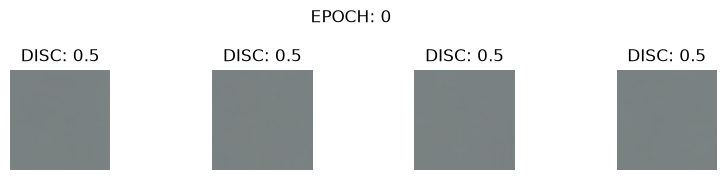

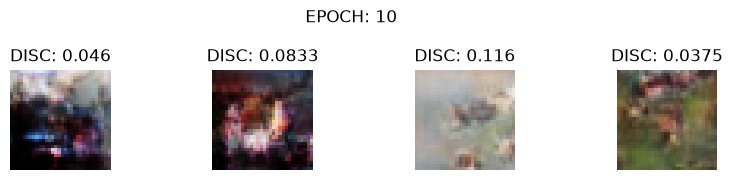

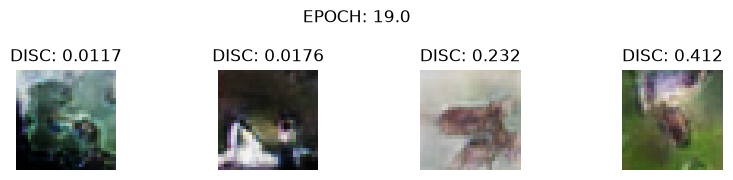

In [219]:
noise_samples = torch.randn((10, 100, 1, 1)).cpu()

for epoch in range(3):
    if (epoch == 2):
        epoch = 1.9
    loaded_gen = Generator().cpu()
    loaded_disc = Discriminator().cpu()

    weights_gen = torch.load(f'D:/MIREA/DPO/Learning/Practic2_12/generator_conv_weights_{int(epoch * 10)}.pt')
    weights_disc = torch.load(f'D:/MIREA/DPO/Learning/Practic2_12/discriminator_conv_weights_{int(epoch * 10)}.pt')

    loaded_gen.load_state_dict(weights_gen)
    loaded_disc.load_state_dict(weights_disc)

    loaded_gen.eval()
    loaded_disc.eval()

    with torch.no_grad():
        generated_samples = loaded_gen(noise_samples)
        disc_output = loaded_disc(generated_samples)
    
    generated_samples = generated_samples.detach()

    generated_samples = (generated_samples + 1.0) / 2.0
    generated_samples = torch.clamp(generated_samples, 0, 1)

    plt.figure(figsize=(10, 6))
    for i in range(4):
        ax = plt.subplot(4, 4, i + 1)
        score = disc_output[i].item()
        ax.set_title(f'DISC: {score:.3}')
        img = generated_samples[i].permute(1, 2, 0).numpy()
        plt.imshow(img, cmap='gray_r')
        plt.axis('off')

    plt.suptitle(f'EPOCH: {epoch * 10}')
    plt.show()

In [196]:
dataset.classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']